#Lab Sheet: 3
## Image Filtering, Edge Detection, Sharpening and Image Enhancement

Name - Vanshika Chauhan

Course - B Tech CSE 3rd year

Subject - Computer Vision

CUID - Cu240250953



### Objective
To implement and analyze different image-processing techniques using Python and OpenCV, including spatial filtering, edge detection, sharpening, convolution, denoising, cartoonification, and quantitative image-quality evaluation using **PSNR** and **SSIM**.

In [ ]:
# COMMON SETUP
# Run this cell first.

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import files
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

print("OpenCV version:", cv2.__version__)
print("Libraries loaded successfully.")

OpenCV version: 5.0.0
Libraries loaded successfully.


## Upload an Input Image

Upload a clear JPG/PNG image. The same image can be used for all experiments.

Saving flower.3.webp to flower.3.webp
Image: flower.3.webp
Shape: (627, 1200, 3)


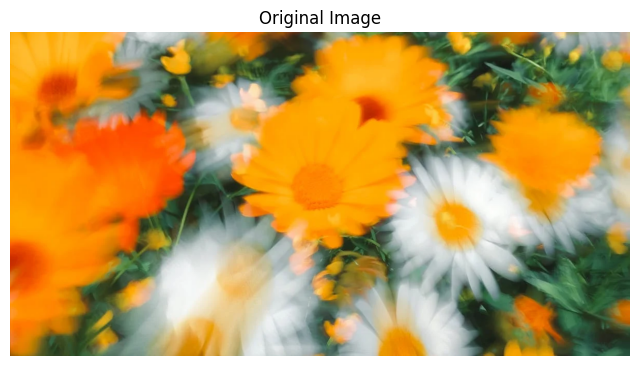

In [ ]:
# Upload an image
uploaded = files.upload()

filename = next(iter(uploaded))
img_bgr = cv2.imread(filename)

if img_bgr is None:
    raise ValueError("Could not read the uploaded image.")

img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

print("Image:", filename)
print("Shape:", img.shape)

plt.figure(figsize=(8, 5))
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.show()

# 1 : Noise Removal Using Gaussian, Median and Mean Filters

### Aim
To build a noise-removal tool using **Gaussian, median, and mean filters** and compare their effectiveness on **salt-and-pepper noise**.

### Theory
- **Mean filter:** Replaces each pixel with the average of neighboring pixels. It smooths noise but can blur edges.
- **Gaussian filter:** Uses a Gaussian-weighted neighborhood and produces smooth results.
- **Median filter:** Replaces a pixel with the median of its neighborhood. It is particularly effective for salt-and-pepper noise.

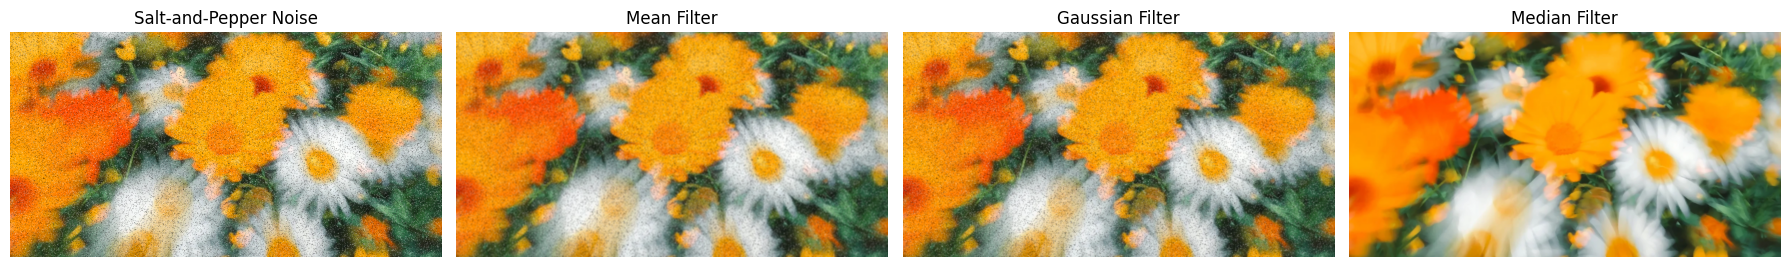

In [ ]:
# Add salt-and-pepper noise
def add_salt_pepper_noise(image, amount=0.05):
    noisy = image.copy()
    h, w = noisy.shape[:2]
    num_pixels = int(amount * h * w)

    # Salt noise
    coords = (np.random.randint(0, h, num_pixels),
              np.random.randint(0, w, num_pixels))
    noisy[coords[0], coords[1]] = 255

    # Pepper noise
    coords = (np.random.randint(0, h, num_pixels),
              np.random.randint(0, w, num_pixels))
    noisy[coords[0], coords[1]] = 0

    return noisy

noisy_sp = add_salt_pepper_noise(img, amount=0.05)

mean_filtered = cv2.blur(noisy_sp, (5, 5))
gaussian_filtered = cv2.GaussianBlur(noisy_sp, (5, 5), 0)
median_filtered = cv2.medianBlur(noisy_sp, 5)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
titles = ["Salt-and-Pepper Noise", "Mean Filter", "Gaussian Filter", "Median Filter"]
images = [noisy_sp, mean_filtered, gaussian_filtered, median_filtered]

for ax, im, title in zip(axes, images, titles):
    ax.imshow(im)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Observation
For salt-and-pepper noise, the **median filter generally preserves edges better and removes impulse noise effectively**, while mean and Gaussian filters may produce more smoothing.

# 2: Edge Detection Using Laplacian and Sobel Filters


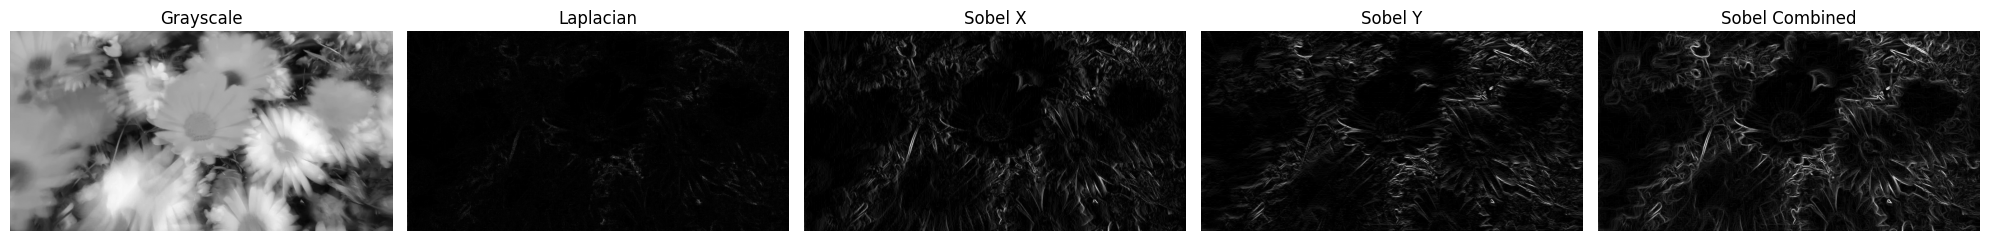

In [ ]:
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

# Laplacian
laplacian = cv2.Laplacian(gray, cv2.CV_64F)
laplacian = cv2.convertScaleAbs(laplacian)

# Sobel X and Y
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

sobel_x = cv2.convertScaleAbs(sobel_x)
sobel_y = cv2.convertScaleAbs(sobel_y)

sobel_combined = cv2.magnitude(
    cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3),
    cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
)
sobel_combined = cv2.convertScaleAbs(sobel_combined)

fig, axes = plt.subplots(1, 5, figsize=(20, 5))
images = [gray, laplacian, sobel_x, sobel_y, sobel_combined]
titles = ["Grayscale", "Laplacian", "Sobel X", "Sobel Y", "Sobel Combined"]

for ax, im, title in zip(axes, images, titles):
    ax.imshow(im, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# 3: Interactive Blur Tool with Adjustable Kernel Size



In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

kernel_slider = widgets.IntSlider(
    value=5, min=1, max=21, step=2,
    description="Kernel:",
    continuous_update=True
)

output = widgets.Output()

def update_blur(change=None):
    k = kernel_slider.value
    blurred = cv2.GaussianBlur(img, (k, k), 0)

    with output:
        clear_output(wait=True)
        plt.figure(figsize=(8, 5))
        plt.imshow(blurred)
        plt.title(f"Gaussian Blur – Kernel Size: {k} × {k}")
        plt.axis("off")
        plt.show()

kernel_slider.observe(update_blur, names="value")
display(kernel_slider, output)
update_blur()

IntSlider(value=5, description='Kernel:', max=21, min=1, step=2)

Output()

# 4: Image Sharpening Using Unsharp Masking


### Formula
**Sharpened Image = Original + α × (Original − Blurred Image)**

where **α** controls the sharpening strength.

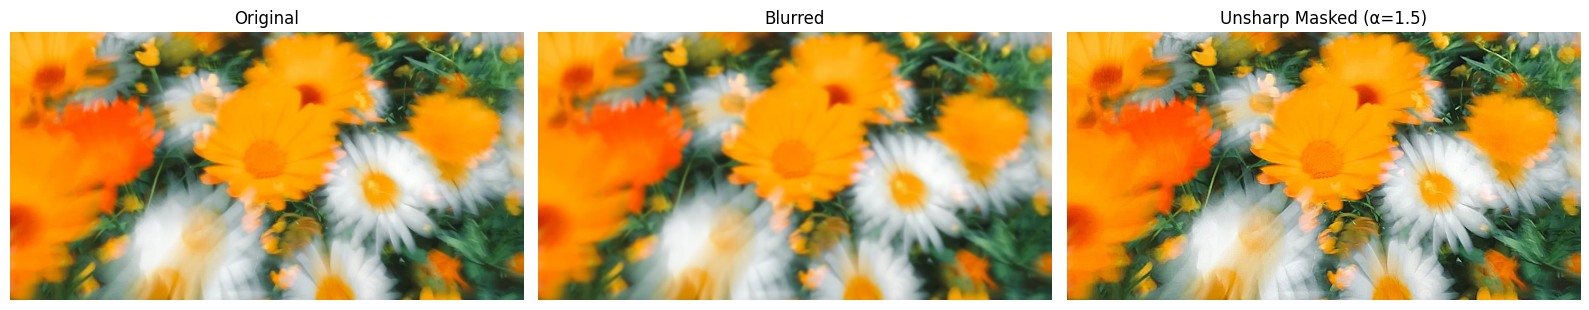

In [ ]:
# Unsharp masking
blurred = cv2.GaussianBlur(img, (0, 0), sigmaX=2)

alpha = 1.5
sharpened = cv2.addWeighted(img, 1 + alpha, blurred, -alpha, 0)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(img)
axes[0].set_title("Original")
axes[1].imshow(blurred)
axes[1].set_title("Blurred")
axes[2].imshow(sharpened)
axes[2].set_title(f"Unsharp Masked (α={alpha})")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# 5: Custom Convolution Kernel Designer

### Aim
To develop a custom convolution kernel designer where the user enters a **3×3 kernel matrix** and applies it to an image.

### Examples
- Sharpening kernel:
  `[[0,-1,0],[-1,5,-1],[0,-1,0]]`
- Edge kernel:
  `[[-1,-1,-1],[-1,8,-1],[-1,-1,-1]]`
- Emboss kernel:
  `[[-2,-1,0],[-1,1,1],[0,1,2]]`

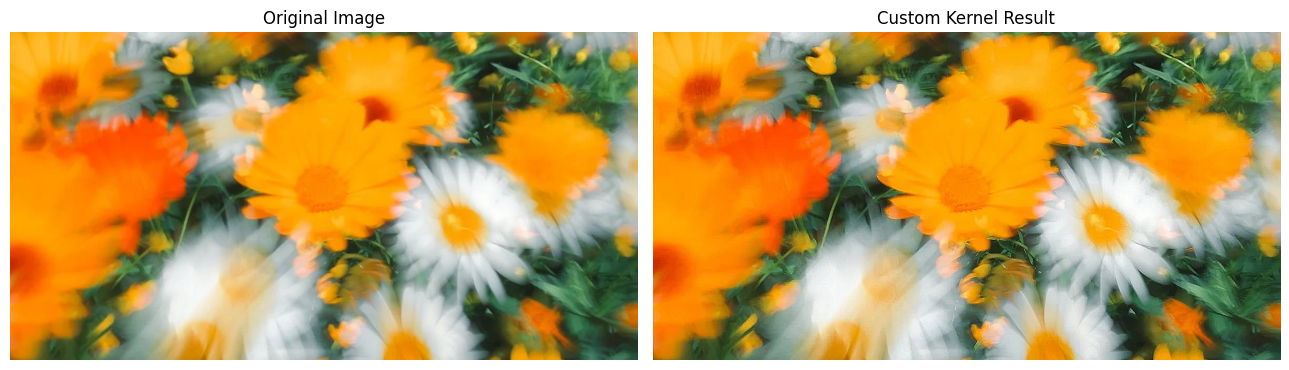

Kernel used:
[[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]]


In [ ]:
# Enter your own 3x3 kernel
kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=np.float32)

result = cv2.filter2D(img, -1, kernel)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(img)
axes[0].set_title("Original Image")
axes[1].imshow(np.clip(result, 0, 255).astype(np.uint8))
axes[1].set_title("Custom Kernel Result")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Kernel used:")
print(kernel)

#  6: Bilateral Filtering vs Gaussian Blur

### Aim
To create a **bilateral filtering demonstration** that smooths an image while preserving edges and compare it with standard Gaussian blur.

### Theory
Bilateral filtering considers both:
1. Spatial distance between pixels.
2. Intensity/color difference between pixels.

Therefore, it can smooth regions while maintaining important edges.

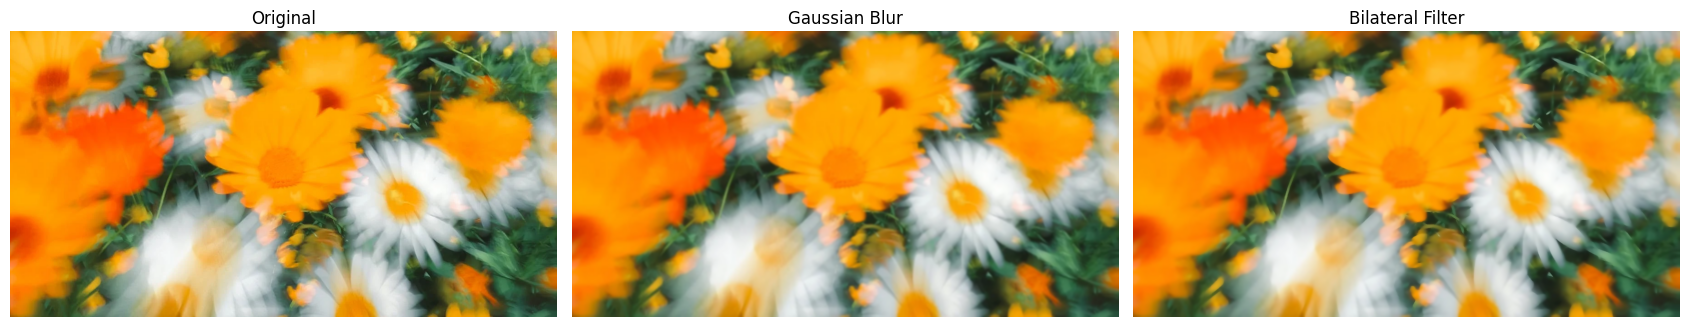

In [ ]:
gaussian = cv2.GaussianBlur(img, (9, 9), 0)

bilateral = cv2.bilateralFilter(
    img,
    d=9,
    sigmaColor=75,
    sigmaSpace=75
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
images = [img, gaussian, bilateral]
titles = ["Original", "Gaussian Blur", "Bilateral Filter"]

for ax, im, title in zip(axes, images, titles):
    ax.imshow(im)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

#  7: Denoising Pipeline for Old / Scanned Photographs

### Aim
To build a denoising pipeline for old or scanned photographs using a **combination of spatial filters**.

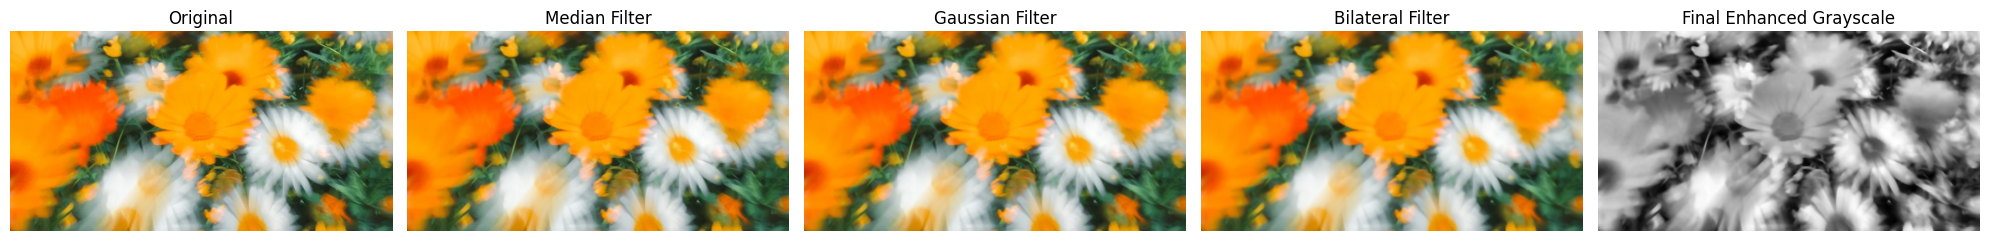

In [ ]:
# Denoising pipeline
step1 = cv2.medianBlur(img, 5)
step2 = cv2.GaussianBlur(step1, (5, 5), 0)
step3 = cv2.bilateralFilter(step2, 9, 60, 60)

# Mild CLAHE enhancement
gray_step3 = cv2.cvtColor(step3, cv2.COLOR_RGB2GRAY)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
enhanced_gray = clahe.apply(gray_step3)

fig, axes = plt.subplots(1, 5, figsize=(20, 5))
images = [img, step1, step2, step3, enhanced_gray]
titles = [
    "Original",
    "Median Filter",
    "Gaussian Filter",
    "Bilateral Filter",
    "Final Enhanced Grayscale"
]

for ax, im, title in zip(axes, images, titles):
    if len(im.shape) == 2:
        ax.imshow(im, cmap="gray")
    else:
        ax.imshow(im)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# 8: Reduction of Simple Motion-Blur Artifacts



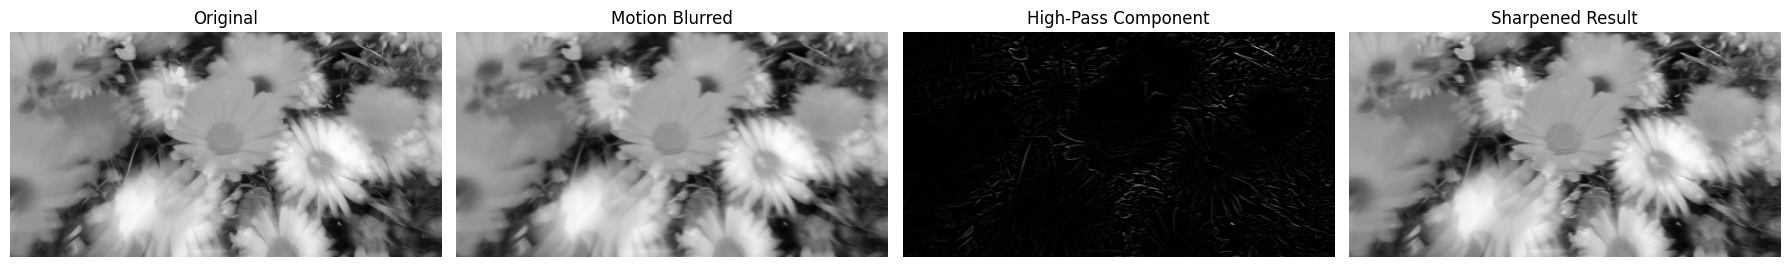

In [ ]:
# Create a simple motion-blurred version for demonstration
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

motion_kernel = np.zeros((9, 9), dtype=np.float32)
motion_kernel[4, :] = 1 / 9

motion_blurred = cv2.filter2D(gray, -1, motion_kernel)

# High-pass component
low_pass = cv2.GaussianBlur(motion_blurred, (0, 0), 2)
high_pass = cv2.subtract(motion_blurred, low_pass)

# Sharpen
sharpened_motion = cv2.addWeighted(motion_blurred, 1.0, high_pass, 2.0, 0)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
images = [gray, motion_blurred, high_pass, sharpened_motion]
titles = ["Original", "Motion Blurred", "High-Pass Component", "Sharpened Result"]

for ax, im, title in zip(axes, images, titles):
    ax.imshow(im, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# 9: Cartoonify Effect Generator

To create a **cartoonify effect** using edge detection combined with smoothing filters.

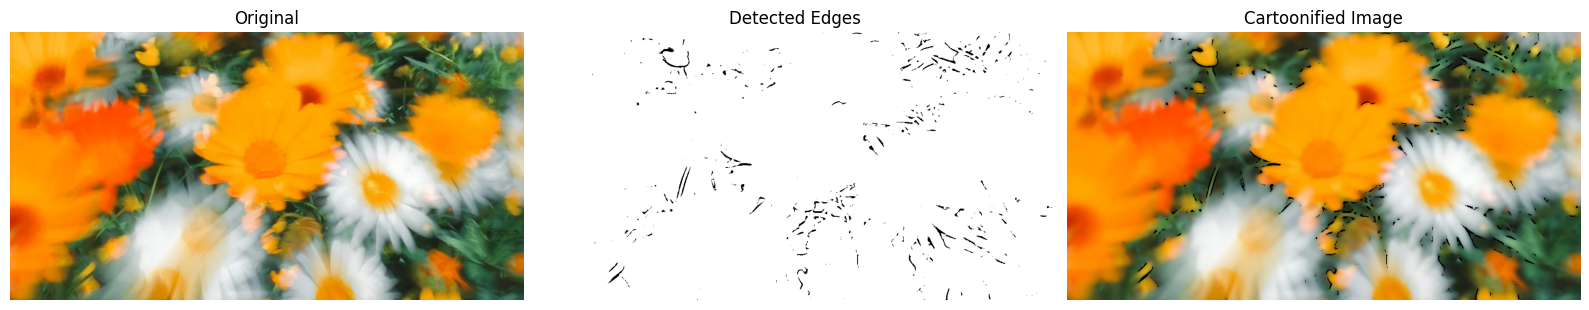

In [ ]:
# Smooth colors while preserving edges
smooth = cv2.bilateralFilter(img, 9, 150, 150)
smooth = cv2.bilateralFilter(smooth, 9, 150, 150)

gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
gray_blur = cv2.medianBlur(gray, 7)

edges = cv2.adaptiveThreshold(
    gray_blur,
    255,
    cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY,
    9,
    9
)

cartoon = cv2.bitwise_and(smooth, smooth, mask=edges)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(img)
axes[0].set_title("Original")
axes[1].imshow(edges, cmap="gray")
axes[1].set_title("Detected Edges")
axes[2].imshow(cartoon)
axes[2].set_title("Cartoonified Image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# 10: PSNR / SSIM Comparison Dashboard

### Aim
To build a comparison dashboard that reports **PSNR** and **SSIM** scores for different filtering techniques applied to the same noisy image.


In [ ]:
# Use the original image as the reference image
reference = img.copy()

# Create a noisy image
noisy = add_salt_pepper_noise(reference, amount=0.05)

# Apply different filters
mean_result = cv2.blur(noisy, (5, 5))
gaussian_result = cv2.GaussianBlur(noisy, (5, 5), 0)
median_result = cv2.medianBlur(noisy, 5)
bilateral_result = cv2.bilateralFilter(noisy, 9, 75, 75)

results = {
    "Noisy": noisy,
    "Mean": mean_result,
    "Gaussian": gaussian_result,
    "Median": median_result,
    "Bilateral": bilateral_result
}

# Calculate PSNR and SSIM
rows = []

for name, result in results.items():
    psnr = peak_signal_noise_ratio(reference, result, data_range=255)

    ssim = structural_similarity(
        reference,
        result,
        channel_axis=2,
        data_range=255
    )

    rows.append({
        "Technique": name,
        "PSNR (dB)": round(psnr, 3),
        "SSIM": round(ssim, 4)
    })

df_metrics = pd.DataFrame(rows)
display(df_metrics)

,Technique,PSNR (dB),SSIM
0,Noisy,14.715,0.1253
1,Mean,26.179,0.5812
2,Gaussian,24.582,0.4600
3,Median,41.537,0.9785
4,Bilateral,14.787,0.1258


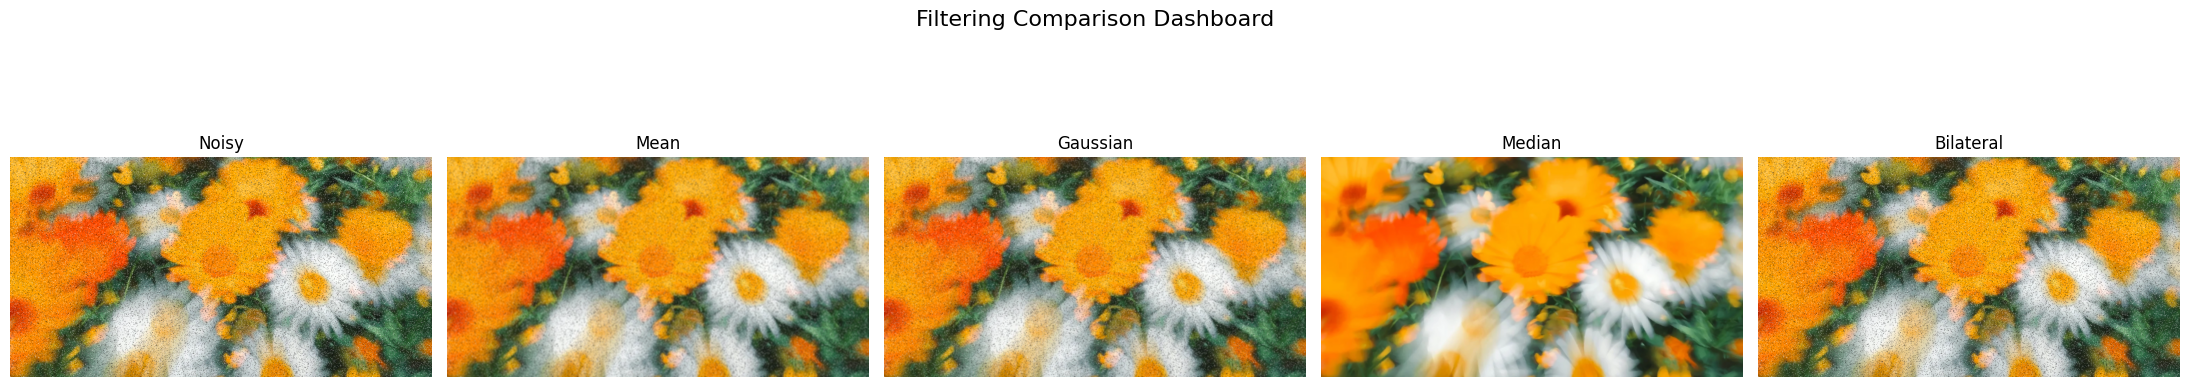

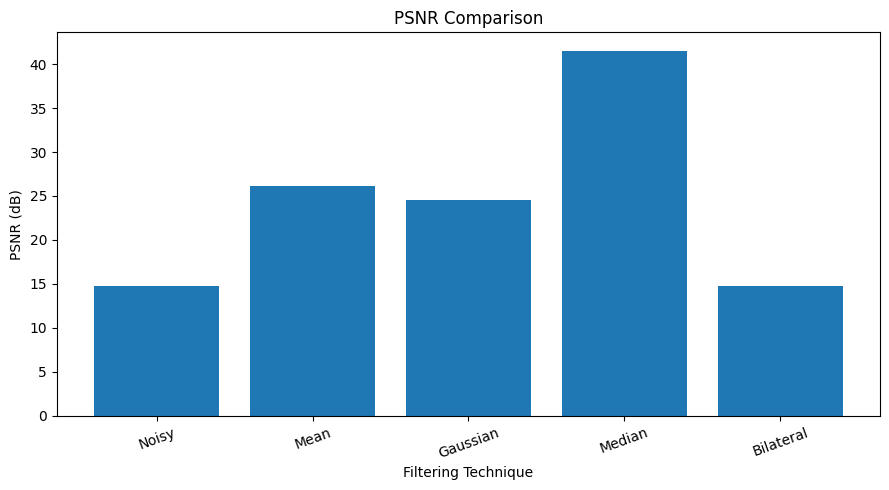

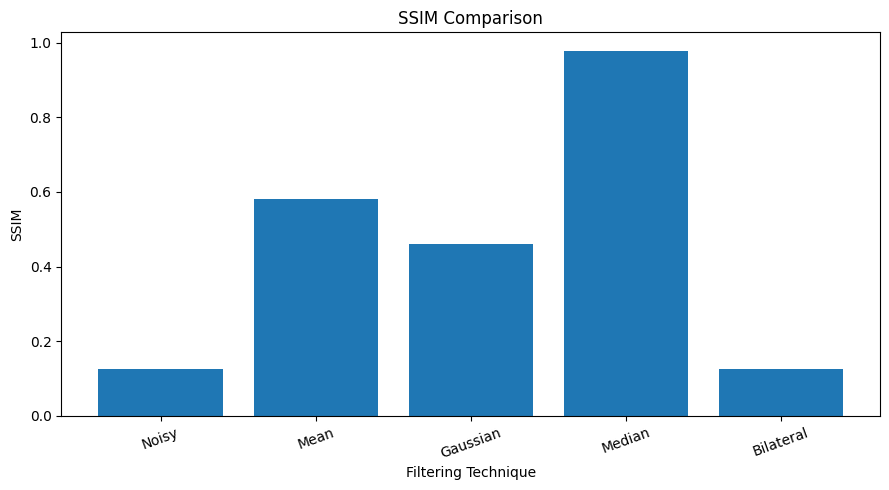

In [ ]:
# Visual comparison dashboard
fig, axes = plt.subplots(1, 5, figsize=(22, 5))

for ax, (name, result) in zip(axes, results.items()):
    ax.imshow(result)
    ax.set_title(name)
    ax.axis("off")

plt.suptitle("Filtering Comparison Dashboard", fontsize=16)
plt.tight_layout()
plt.show()

# Bar charts for PSNR and SSIM
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(df_metrics["Technique"], df_metrics["PSNR (dB)"])
ax.set_title("PSNR Comparison")
ax.set_ylabel("PSNR (dB)")
ax.set_xlabel("Filtering Technique")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(df_metrics["Technique"], df_metrics["SSIM"])
ax.set_title("SSIM Comparison")
ax.set_ylabel("SSIM")
ax.set_xlabel("Filtering Technique")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()